## Environment Setup

In [2]:
import os
import json
import xpd_tools
# from tkinter.constants import N
import pandas as pd
import numpy as np

## Materials Project

Get some data from Materials Project to run. We will interpolate between the points adn use it as a sample target for BLOP

In [3]:
from dotenv import load_dotenv
import os

load_dotenv()
MP_API_KEY = os.environ["MP_API_KEY"]


## AGENT - Initialization

### Initialize the Agent and set the logical paths and globals of our system.

For Bluesky:
- Queueserver toggle
- Tiled profile

Other:
- HTTP API and Server uri's
- ZMQ consumer addresses

Evaluation methods:
- xray, uvvis, or xray-uvis


In [4]:
from xpd_tools.optimization.agent import BuildAgent

# Queueserver connection -- unused on this build_local() path, kept here
# only because HTTP_SERVER_URI/HTTP_API_KEY/ZMQ_CONSUMER_ADDR are read from
# the environment below regardless.
HTTP_SERVER_URI = os.environ.get(
    "QSERVER_HTTP_URI", 
    "https://xf28id2-xpd-qs1.nsls2.bnl.gov"
    )
HTTP_API_KEY = os.environ.get(
    "QSERVER_HTTP_SERVER_API_KEY", 
    ""
    )
ZMQ_CONSUMER_ADDR = os.environ.get(
    "ZMQ_CONSUMER_ADDR",
    "ipc:///var/lib/bluesky-zmq-proxy/xpd-ipc-in-ipc-out/out.sock",
    )

# Historical data path
AGENT_DATA_PATH = "data/halide_data_uvvis_only.csv"
# AGENT_DATA_PATH = None

# Tiled URI for evaluation function
TILED_URI = os.environ.get(
    "TILED_URI", 
    "https://tiled.nsls2.bnl.gov"
    )
TILED_PROFILE = os.environ.get(
    "TILED_PROFILE", 
    "xpd"
    )

build_agent = BuildAgent(
    # False -- this notebook exercises build_local(), the no-queue-server
    # path (drives a local RunEngine directly instead of dispatching
    # acquisition plans by name through a Queue Server). build() (the
    # queue_server=True path) is what examples/halide_example_class.ipynb
    # demonstrates instead.
    queue_server = False,
    # Agent
    agent_data_path = AGENT_DATA_PATH,
    # Http 
    http_server_uri = HTTP_SERVER_URI,
    http_api_key = HTTP_API_KEY,
    # ZMQ
    zmq_consumer_address = ZMQ_CONSUMER_ADDR,
    # Tiled
    tiled_profile = TILED_PROFILE,
    # Evaluation Method
    evaluation_method = 'uvvis'
)


# Provide the agent some metadata
build_agent.set_metadata({
    "beamline": "28id2",
    "tags": ["qserver", "bluesky"],
    "comment": "Halide Synthesis Test"
    })
print(build_agent.metadata_string)

/Users/thomasbarrett/Documents/.venv/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[INFO 10-22 15:09:24] ax.storage.sqa_store.with_db_settings_base: Ax SQL storage initialized with SQLAlchemy 2.1.4


beamline: 28id2
tags: ['qserver', 'bluesky']
comment: Halide Synthesis Test



## BEAMLINE - UVvis Screening

In [5]:
# Optimization Parameters
PEAK_TARGET         = 520   # nm
PEAK_TOLERANCE      = 5     # nm

from xpd_tools.optimization.helpers.qepro import PlqyReference, SpectraFitSettings

build_agent.set_uvvis_objectives(
    # Objective Target
    peak_target             = PEAK_TARGET,
    peak_tolerance          = PEAK_TOLERANCE,
    max_peak_distance_nm    = PEAK_TOLERANCE*10,
    min_plqy                = 1e-3,
    max_fwhm_nm             = 60,
    # Retries
    max_retries             = 10,
    retry_delay             = 2.0,
    # Screening, data selection, and fitting windows
    fit_settings = SpectraFitSettings(
        pl_screen_key_height        = 200,
        pl_screen_peak_height       = 50,
        pl_screen_peak_distance     = 100,
        pl_percent_range            = (40, 100),
        pl_wavelength_range         = (400, 800),
        pl_fit_maxfev               = 100000,
        pl_fit_r2_window_sigma      = 3,
        absorbance_percent_range    = (10, 70),
        absorbance_wavelength_range = (210, 700),
    ),
    # Calibration Standard Reference (reference_type defaults to "quinine")
    plqy = PlqyReference(
        excitation_wavelength_nm   = 365,
        absorbance                 = 0.361,
        pl_integral                = 952628,
        refractive_index           = 1.337,
        plqy                       = 0.546,
        solvent_refractive_index   = 1.506,
    ),
)

print(build_agent.fit_settings)
print(build_agent.plqy)

SpectraFitSettings(pl_screen_key_height=200, pl_screen_peak_height=50, pl_screen_peak_distance=100, pl_percent_range=(40, 100), pl_wavelength_range=(400, 800), pl_fit_maxfev=100000, pl_fit_r2_window_sigma=3, absorbance_percent_range=(10, 70), absorbance_wavelength_range=(210, 700))
PlqyReference(reference_type='quinine', excitation_wavelength_nm=365, absorbance=0.361, pl_integral=952628, refractive_index=1.337, plqy=0.546, solvent_refractive_index=1.506)


## BLOP - DOFs

Degrees of freedom that BLOP can modify

In [6]:
# Set the Agent DOFs
from xpd_tools.optimization.helpers.dofs import Pump

build_agent.set_dofs(
    pumps = [
      Pump(
        name = "CsPb",
        bounds = (10, 250),
        id = "dds2_p1"
      ),
      Pump(
        name = "Br",
        bounds = (0, 250),
        id = "dds2_p2"
      ),
      Pump(
        name = "Cl",
        bounds = (0, 250),
        id = "dds3_p1"
      ),
      Pump(
        name = "I",
        bounds = (0, 250),
        id = "dds3_p2"
      ),
      # Pump(
      #   name = "OAm",
      #   bounds = (0, 200),
      #   id = "dds3_p3"
      # ),
      
    ]
  )
print(build_agent.dofs)

[RangeDOF(name='infusion_rate_CsPb', actuator=None, bounds=(10, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_Br', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_Cl', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None), RangeDOF(name='infusion_rate_I', actuator=None, bounds=(0, 250), parameter_type='float', step_size=None, scaling=None)]


## BEAMLINE - Experimental Harware Parameters

In [7]:
from xpd_tools.optimization.plans import FlowSource, DilutionStage, WashCycle

# loaded_ml: mL filled into each syringe (placeholder = target_ml; set on the day)
build_agent.experiment(
    sources = [
        FlowSource(
            dof="infusion_rate_CsPb",
            pump='dds2_p1',
            precursor="CsPb",
            sample_label="Cs-rich 33mM",
            loaded_ml=30.0,
        ),
        FlowSource(
            dof="infusion_rate_Br",
            pump='dds2_p2',
            precursor="Br",
            sample_label="TOABr",
            loaded_ml=30.0,
        ),
        FlowSource(
            dof="infusion_rate_Cl",
            pump='dds3_p1',
            precursor="Pb",
            sample_label="Pb-rich 33mM",
            loaded_ml=30.0,
                ),
        FlowSource(
            dof="infusion_rate_I",
            pump='dds3_p2',
            precursor="I",
            sample_label="I",
            loaded_ml=30.0,
        ),
        # FlowSource(
        #     dof="infusion_rate_OAm",
        #     pump='dds3_p3',
        #     precursor="OAm",
        #     sample_label="OAm",
        #     loaded_ml=30.0,
        # ),
    ],
    dilutions = [
        DilutionStage(
            pump='dds1_p1',
            ratio=1.0,
            position="before_equilibrium",
            syringe_ml=20,
            material="plastic_BD",
            target_ml=20,
            loaded_ml=20.0,
        ),
        DilutionStage(
            pump='ultra2',
            ratio=1.0,
            position="after_equilibrium",
            syringe_ml=100,
            material="steel",
            target_ml=100,
            loaded_ml=100.0,
            wait_sec=30,
        ),
    ],
    wash_cycles=[
        WashCycle(pump='ultra1', loaded_ml=30.0),
    ]
)

## BLOP - Historical data and run settings

In [8]:
# Historical data (AGENT_DATA_PATH, above) is loaded by build()/build_local():
# peak_distance is recomputed from Peak with the configured peak_target, and rows
# with NaN/inf are dropped (an error if that leaves none). How the campaign runs
# is the agent's run settings: to_config() saves them as the JSON's "run" section,
# and from_config() / xpd-autonomous-server read them back.
RUN = dict(
    iterations=150,
    extra_initialization_trials=5,  # initialization_budget = historical trials + this
    generation_strategy={
        "initialize_with_center": False,
        "min_observed_initialization_trials": 2,
        "allow_exceeding_initialization_budget": True,
    },
)
build_agent.set_run(**RUN)
print(build_agent.run_settings)

RunSettings(iterations=150, n_points=1, extra_initialization_trials=5, generation_strategy={'initialize_with_center': False, 'min_observed_initialization_trials': 2, 'allow_exceeding_initialization_budget': True}, local=LocalRunSettings(mixer_lengths_cm=(0.0,), residence_time_ratio=0.0, simulated=None, skip_waits=True))


## BLOP - Build and Run Agent

In [9]:
from bluesky.run_engine import RunEngine
from xpd_tools.optimization.simulation import (
    build_simulated_tiled_clients,
)
from xpd_tools.optimization.legacy import (
    build_xpd_objects,
    skip_waits,
)

DOF_FOR_PHASE = {
    "CsBr": "infusion_rate_Br", #
    "CsPbBr3": "infusion_rate_CsPb", # Bandgap - 2.29-2.34, Red
    "CsPbI3": "infusion_rate_I", # Bandgap - 1.63-1.75, 
    "CsPbCl3": "infusion_rate_Cl", # Bandgap - 2.90-3.03, 
    # "Cs4PbBr6": "infusion_rate_OAm", # 0-D
}

# Per-phase PL width/absorbance -- toy placeholders, mixed by the same weights as the band gap.
PL_FWHM_NM_FOR_PHASE = {
    "CsPbBr3":  20.0,
    "CsPbI3":   30.0,
    "CsPbCl3":  10.0,
    "CsBr":     15.0,
    "Cs4PbBr6": 25.0,
}

ABSORBANCE_FOR_PHASE = {
    "CsPbBr3":  0.2,
    "CsPbI3":   0.2,
    "CsPbCl3":  0.2,
    "CsBr":     0.2,
    "Cs4PbBr6": 0.2,
}

# Clamp for 1240/mixed_band_gap_eV -- classify_pl hardcodes a >=400nm
# floor (treats shorter as an LED artifact), and CsBr's real (ionic salt)
# band gap alone can push the mixed peak well below that. Keep a 10nm
# margin above the floor and below fit_settings' pl_wavelength_range=(400,800).
PEAK_NM_RANGE = (410.0, 780.0)

# Only CsPbBr3 (the wanted phase) is PL-emissive -- CsBr/Cs4PbBr6 are dark and shouldn't pull the PL peak.
PL_PHASES = {
    "CsPbBr3":2.29,
    "CsPbI3":1.63,
    "CsPbCl3":2.90
    }

# Shared across scattering/PL/absorbance -- small relative to absorbance's ~0.2-0.4 scale, negligible for the others.
NOISE_LEVEL = 0.1

RE = RunEngine()

# The simulation settings are part of the run settings, so the saved JSON (and
# the GUI) simulate exactly this. The MP API key stays out: it's read from MP_API_KEY.
build_agent.set_run(
    **RUN,
    local={
        "simulated": {
            "dof_for_phase": DOF_FOR_PHASE,
            "pl_fwhm_nm": PL_FWHM_NM_FOR_PHASE,
            "pl_alloy": list(PL_PHASES.keys()),
            "band_gap_ev": PL_PHASES,
            "absorbance_value": ABSORBANCE_FOR_PHASE,
            "peak_nm_range": list(PEAK_NM_RANGE),
            "noise_level": NOISE_LEVEL,
        },
    },
)
# Plan waits (dilution, wash, settling) are hardware timing: instant in a simulation
# unless run.local.skip_waits is False (e.g. to exercise the syringe refill check).
if build_agent.run_settings.local.skip_waits:
    skip_waits(RE)

tiled_client, sandbox_client = build_simulated_tiled_clients(
    RE,
    phases=build_agent.phases,
    mp_api_key=MP_API_KEY,
    **build_agent.run_settings.local.simulated,
)


Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

...

Retrieving MaterialsDoc documents:   0%|          | 0/1 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/2 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/4 [00:00<?, ?it/s]

In [10]:
from xpd_tools.optimization.legacy import (
    identity_wrap_xray_run
)

run_agent = build_agent.build_local(
    devices=build_xpd_objects(),
    wrap_xray_run=identity_wrap_xray_run,
    # Real hardware defaults (30cm mixer, 
    # ratio=1.0) compute a real
    # multi-minute equilibrium wait from the pump rate -- zero them out
    # for a fast local/simulated run.
    mixer_lengths_cm=build_agent.run_settings.local.mixer_lengths_cm,
    residence_time_ratio=build_agent.run_settings.local.residence_time_ratio,
    tiled_client=tiled_client,
    sandbox_client=sandbox_client,
)

[INFO 10-22 15:09:27] ax.api.client: Trial 0 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 1 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 2 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 3 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 4 marked COMPLETED.
/Users/thomasbarrett/Documents/.venv/lib/python3.14/site-packages/ax/api/client.py:610: RuntimeWarning: Parameterization {'infusion_rate_CsPb': 9.9, 'infusion_rate_Br': 29.7, 'infusion_rate_Cl': 44.55, 'infusion_rate_I': 0.0} is in out-of-design. Ax will still attach the trial for use in candidate generation.
  _, trial_index = self._experiment.attach_trial(
[INFO 10-22 15:09:27] ax.api.client: Trial 5 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 6 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 7 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 8 marked COMPLETED.
[INFO 10-22 15:09:27] ax.api.client: Trial 9 marked COMPLETED.
/Users/th

In [11]:
# Generation strategy from the run settings (the same call xpd-autonomous-server
# makes): initialization_budget = historical trials + extra_initialization_trials.
n_historical = build_agent.configure_generation_strategy(run_agent)
print(f"{n_historical} historical trials ingested")

[INFO 10-22 15:09:28] ax.api.client: GenerationStrategy(name='Sobol+MBM:fast', nodes=[GenerationNode(name='Sobol', generator_specs=[GeneratorSpec(generator_enum=Sobol, generator_key_override=None)], transition_criteria=[MinTrials(transition_to='MBM'), MinTrials(transition_to='MBM')], suggested_experiment_status=ExperimentStatus.INITIALIZATION, pausing_criteria=None), GenerationNode(name='MBM', generator_specs=[GeneratorSpec(generator_enum=BoTorch, generator_key_override=None)], transition_criteria=None, suggested_experiment_status=ExperimentStatus.OPTIMIZATION, pausing_criteria=None)]) chosen based on user input and problem structure.


154 historical trials ingested


In [12]:
# Save the config, including its "run" section, for xpd-autonomous-server.
build_agent.to_config("halide_local.json")

### BLOP - Run

In [13]:
RE(run_agent.optimize(
    iterations=build_agent.run_settings.iterations, 
    n_points=build_agent.run_settings.n_points
    )
)

╭───────────────────────────────────────────────── Optimization ──────────────────────────────────────────────────╮
│ Optimizer  AxOptimizer                                                                                          │
│ Actuators  N/A                                                                                                  │
│ Sensors    N/A                                                                                                  │
│ Iterations 150                                                                                                  │
│ Run UID    4592d336-d800-4c44-bf99-7b0271b0abdb                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

[INFO 10-22 15:09:28] ax.api.client: Generated new trial 154 with parameters {'infusion_rate_CsPb': 222.833657, 'infusion_rate_Br': 201.1953, 'infusion_rate_Cl': 8.668615, 'infusion_rate_I': 62.372219} using GenerationNode Sobol.
[INFO 10-22 15:09:28] ax.api.client: Trial 154 marked COMPLETED.


──────────────────────────────────────────────── Iteration 1 / 150 ────────────────────────────────────────────────

  Acquire UID  abe6e99d-73e1-4b0e-b42f-0bef642e2caf

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┓
┃ … ┃ Suggestio… ┃ infusion_ra… ┃ infusion_rat… ┃ infusion_rate… ┃ infusion_ra… ┃ Pe… ┃ log_… ┃ log… ┃ peak_dist… ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━━━━━┩
│ 0 │        154 │      201.195 │       8.66862 │        222.834 │      62.3722 │ 57… │ 3.08… │ -23… │    51.9783 │
└───┴────────────┴──────────────┴───────────────┴────────────────┴──────────────┴─────┴───────┴──────┴────────────┘

...

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━┳━━━━━━━━━━━━┓
┃ … ┃ Suggestio… ┃ infusion_ra… ┃ infusion_rat… ┃ infusion_rate… ┃ infusion_ra… ┃ Pe… ┃ log_… ┃ log… ┃ peak_dist… ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━╇━━━━━━━━━━━━┩
│ 0 │        303 │      37.2124 │       237.968 │        129.467 │      140.364 │ 51… │ 2.89… │ -1.… │    1.91467 │
└───┴────────────┴──────────────┴───────────────┴────────────────┴──────────────┴─────┴───────┴──────┴────────────┘

Peak  min: 410  max: 669.131  mean: 517.121
  log_FWHM  min: 2.70814  max: 3.2817  mean: 2.8939
  log_PLQY  min: -23.0259  max: 1.25793  mean: -3.29023
  peak_distance  min: 0.0545081  max: 149.131  mean: 10.4171
  (150 pts sampled)

                                 Summary Statistics                                  
┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┓
┃ Name               ┃ Type    ┃       Min ┃     Max ┃     Mean ┃       Std ┃ Count ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━┩
│ infusion_rate_Br   │ param   │         0 │     250 │  103.386 │    68.731 │   150 │
│ infusion_rate_Cl   │ param   │         0 │     250 │  175.934 │   65.1539 │   150 │
│ infusion_rate_CsPb │ param   │        10 │     250 │  99.6789 │    65.748 │   150 │
│ infusion_rate_I    │ param   │         0 │ 231.324 │  106.862 │   40.9543 │   150 │
│ Peak               │ outcome │       410 │ 669.131 │  517.121 │   24.4208 │   150 │
│ log_FWHM           │ outcome │   2.70814 │  3.2817 │   2.8939 │ 0.0632184 │   150 │
│ log_PLQY           │ outcome │  -23.0259 │ 1.25793 │ -3.29023 │    6.6332 │   150 │
│ peak_distance      │ outcome │ 0.0545081 │ 149.131 │  10.4171 │   22.2593 │   150 │
└────────────────────┴─────────┴───────────┴─────────┴──────────┴───────────┴───────┘

────────────────────────────────────────────── Optimization Complete ──────────────────────────────────────────────

('4592d336-d800-4c44-bf99-7b0271b0abdb',
 'abe6e99d-73e1-4b0e-b42f-0bef642e2caf',
 'bf9d65ac-3865-47e3-9e54-c1881587f8d8',
 '9e34bb6d-4854-4df0-a4cf-3ce89cb533ac',
 '46a51b84-f09e-43a8-9a59-464a3764f7d7',
 'd3f7e93b-d743-4337-accf-343754292001',
 '060ad0d6-2ab1-4511-8663-90d64a1242df',
 '4e8732a9-80f1-4836-845f-8ee25a4241a2',
 'e47d6af7-5e89-48e4-b72c-e75b8c232cfb',
 'bd02c507-090a-46d2-953d-2ccd885cc69d',
 '18f7e86c-bfa9-4508-ba0a-9dc2061bd2e0',
 '5bf65821-f780-477a-ba5e-9f024394aa30',
 'f57a981e-b4e8-4351-ae75-ea403ad7dc80',
 '7ee768ca-cd39-4098-8b34-e2dfb6bcb10a',
 '039656b2-6e8b-456d-acdd-8a1272ba35bd',
 '2e50de17-88ae-47f4-91ef-836fa4b38b5d',
 'db695fc9-9940-4324-92df-8a04a324a4d5',
 '9569baef-0042-4625-b9a8-9afaba4430a6',
 '1cbe382a-dc4f-40fd-bbb7-05da7f4c3aa2',
 '4746c02c-437a-434d-ad6b-e775b8aa9a52',
 '54ffbeca-9d49-4d83-b7b2-2e33bc5285cc',
 '43e61ab1-14d8-46bf-aa0b-e1fff7f5de3b',
 '7a4d6b57-4128-4815-a469-987050650e9c',
 '9b7232a1-a446-431b-8af5-d8ebf1b45672',
 '5e0b1c67-5e37-

## Summarize and Export Data

In [14]:
from pathlib import Path

Path("tmp/output").mkdir(parents=True, exist_ok=True)
df = run_agent.ax_client.summarize()
df.to_csv("tmp/output/agent_halide_data_mp.csv")

index = df["trial_index"]
peaks = df['Peak']
fwhms = df['log_FWHM']
plqys = df['log_PLQY']

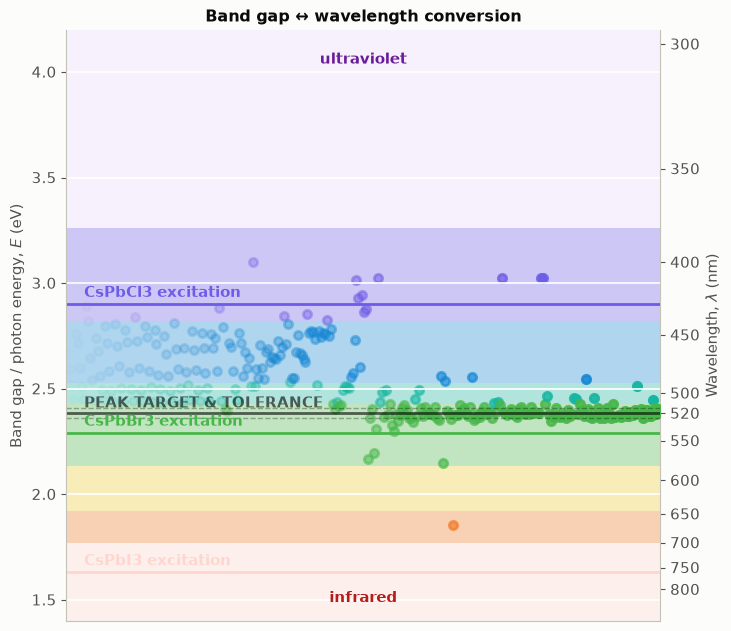

In [21]:
"""Plot the nonlinear band-gap (eV) to wavelength (nm) conversion.
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


HC_EV_NM = 1239.841984  # Planck's constant times c, in eV nm


def wavelength_nm(bandgap_ev):
    """Convert photon energy / optical band gap in eV to wavelength in nm."""
    return HC_EV_NM / np.asarray(bandgap_ev)


def bandgap_ev(wavelength):
    """Convert wavelength in nm to photon energy in eV."""
    # Matplotlib may briefly ask the inverse transform about zero while it
    # lays out the secondary axis.  Infinity is the physically correct limit.
    with np.errstate(divide="ignore", invalid="ignore"):
        return HC_EV_NM / np.asarray(wavelength)


def wavelength_color(wavelength):
    """Approximate visible-light RGB color; UV/IR are deliberately pale."""
    if wavelength < 380:
        return "#eadcff"  # ultraviolet
    if wavelength < 440:
        return "#6c5ce7"
    if wavelength < 490:
        return "#1687d4"
    if wavelength < 510:
        return "#16b6a0"
    if wavelength < 580:
        return "#48b749"
    if wavelength < 645:
        return "#f2ce31"
    if wavelength <= 700:
        return "#f07824"
    return "#ffd6cf"  # infrared


def main():
    e_min, e_max = 1.4, 4.2
    fig, ax = plt.subplots(figsize=(7.2, 6.2), constrained_layout=True)

    # A color strip whose position is computed from wavelength, not drawn on a
    # linear wavelength scale. This is the key detail in a dual eV/nm plot.
    wavelengths = np.linspace(wavelength_nm(e_max), wavelength_nm(e_min), 500)
    for lower, upper in zip(wavelengths[:-1], wavelengths[1:]):
        midpoint = (lower + upper) / 2
        ax.axhspan(
            bandgap_ev(upper), bandgap_ev(lower),
            color=wavelength_color(midpoint), alpha=0.33, linewidth=0, zorder=0,
        )

    ax.set_xlim(0, 1)
    ax.set_xticks([])
    ax.set_ylim(e_min, e_max)
    ax.set_ylabel("Band gap / photon energy, $E$ (eV)")
    ax.set_title("Band gap ↔ wavelength conversion")
    ax.grid(axis="y", color="white", linewidth=1.2)

    right = ax.secondary_yaxis("right", functions=(wavelength_nm, bandgap_ev))
    right.set_ylabel("Wavelength, $\\lambda$ (nm)")
    right.set_yticks([300, 350, 400, 450, 500, 520, 550, 600, 650, 700, 750, 800])

    # Reference values relevant to a 473 nm-excited, ~520 nm-emitting sample.
    # BANDGAP_FOR_PHASE = {
    #         "CsPbBr3": 2.29, # Bandgap - 2.29-2.34, Red
    #         "CsPbI3": 1.63, # Bandgap - 1.63-1.75, 
    #         "CsPbCl3": 2.90, # Bandgap - 2.90-3.03
    #     }

    # Demonstrate Target and Range
    ax.text(0.03, bandgap_ev(PEAK_TARGET+PEAK_TOLERANCE) + 0.05, "PEAK TARGET & TOLERANCE", color='k', alpha=0.6, weight="bold")
    ax.axhline(bandgap_ev(PEAK_TARGET+PEAK_TOLERANCE), linestyle='--', color='k', alpha = 0.3, linewidth=1)
    ax.axhline(bandgap_ev(PEAK_TARGET), linestyle='-', color='k', alpha = 0.6, linewidth=2)
    ax.axhline(bandgap_ev(PEAK_TARGET-PEAK_TOLERANCE), linestyle='--', color='k', alpha = 0.3, linewidth=1)


    # Demonstrate Reference Values for pure crystals
    references = [
        (2.29, "CsPbBr3 excitation", wavelength_color(1240/2.29)),
        (1.63, "CsPbI3 excitation", wavelength_color(1240/1.63)),
        (2.90, "CsPbCl3 excitation", wavelength_color(1240/2.90)),
    ]

    ind_max = np.max(index)
    for ind, peak in zip(index, peaks):
        ax.scatter(ind/ind_max, bandgap_ev(peak), color=wavelength_color(peak), alpha=ind/ind_max, linewidth=2)


    for energy, label, color in references:
        ax.axhline(energy, color=color, linewidth=2)
        ax.text(0.03, energy + 0.035, label, color=color, weight="bold")

    ax.text(0.5, 4.04, "ultraviolet", ha="center", color="#6a1b9a", weight="bold")
    ax.text(0.5, 1.49, "infrared", ha="center", color="#b71c1c", weight="bold")

main()

/var/folders/9p/43jfw_2x5yn4fv6w553vzl4m0000gq/T/ipykernel_92890/2263584702.py:64: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  pts = y[: i + 1][torch.from_numpy(feasible[: i + 1])]




Pareto-optimal trials (on target, observed):
  trial 156: Peak 515.5 nm, log_PLQY -1.60, log_FWHM 2.89  <- CsPb 77.7, Br 138.2, Cl 124.1, I 67.7
  trial 168: Peak 520.5 nm, log_PLQY -1.90, log_FWHM 2.90  <- CsPb 10.0, Br 13.0, Cl 94.8, I 64.0
  trial 174: Peak 517.1 nm, log_PLQY -1.74, log_FWHM 2.89  <- CsPb 81.0, Br 123.5, Cl 237.5, I 143.9
  trial 185: Peak 519.8 nm, log_PLQY -1.24, log_FWHM 2.90  <- CsPb 127.7, Br 22.0, Cl 233.2, I 142.5
  trial 202: Peak 516.7 nm, log_PLQY -1.68, log_FWHM 2.88  <- CsPb 10.2, Br 114.1, Cl 250.0, I 161.0
  trial 212: Peak 517.9 nm, log_PLQY -1.28, log_FWHM 2.89  <- CsPb 60.0, Br 81.3, Cl 107.3, I 62.8
  trial 216: Peak 518.4 nm, log_PLQY -1.38, log_FWHM 2.90  <- CsPb 123.4, Br 37.6, Cl 229.7, I 136.5
  trial 219: Peak 518.6 nm, log_PLQY -0.94, log_FWHM 2.90  <- CsPb 68.7, Br 23.8, Cl 103.8, I 60.3
  trial 224: Peak 519.8 nm, log_PLQY -0.58, log_FWHM 2.90  <- CsPb 170.9, Br 234.8, Cl 207.0, I 119.5
  trial 226: Peak 518.7 nm, log_PLQY -23.03, log_FW

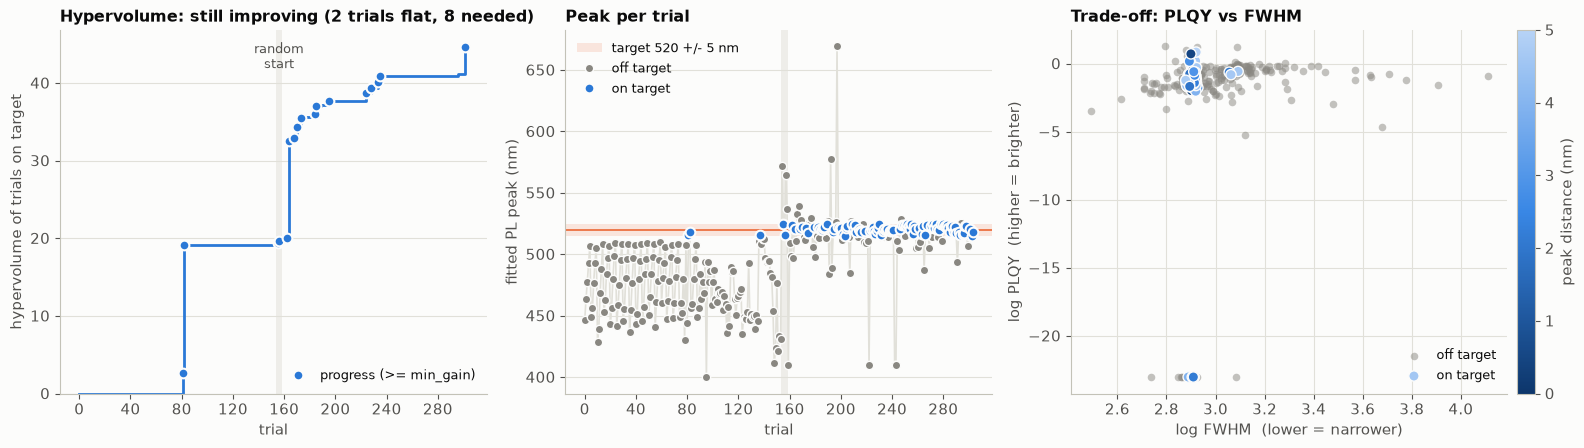

In [16]:
"""
Has a UV-Vis campaign converged? Tracks the hypervolume of the trials within peak_target +/- peak_tolerance.

The agent's three objectives (log_FWHM down, log_PLQY up, peak_distance down) trade off against each other, so
individual trials keep moving after the job is done. Convergence is the Pareto front no longer improving: the
hypervolume it dominates above a fixed reference point has not grown by min_gain in patience model trials.

df = check_convergence(build_agent, run_agent)                         # table, verdict, Pareto trials, plots
df = check_convergence(build_agent, run_agent, save="convergence.png") # also writes the figure
"""
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from botorch.utils.multi_objective.hypervolume import Hypervolume
from botorch.utils.multi_objective.pareto import is_non_dominated
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list("blues", ["#0d366b", "#3987e5", "#b7d3f6"])  # dark = on target


def check_convergence(
    build_agent,
    run_agent,
    ref: dict[str, float] | None = None,
    min_gain: float = 0.01,
    patience: int = 8,
    plot: bool = True,
    save: str | None = None,
) -> pd.DataFrame:
    """
    Print the hypervolume trace, whether it has converged and the Pareto-optimal trials; plot them; return the trace.

    Args:
        - build_agent, run_agent: the notebook's BuildAgent and the agent build_local() returned
        - ref: reference point, the worst values you'd still accept; default FWHM 60 nm, PLQY 1e-3 and
          peak_distance = peak_tolerance. Only trials better on every objective add hypervolume; keep it
          fixed for a campaign, since changing it rescales the hypervolume
        - min_gain: a trial counts as progress if it grows the hypervolume by at least this fraction
        - patience: this many model (non-Sobol) trials in a row without progress = converged
        - plot: draw the hypervolume trace, Peak per trial and the PLQY/FWHM trade-off
        - save: also write the figure to this path

    Returns:
        - the completed trials with feasible, hypervolume, improved and pareto columns
    """
    target, tol = build_agent.peak_target, build_agent.peak_tolerance
    ref = ref or {"log_FWHM": np.log(60.0), "log_PLQY": np.log(1e-3), "peak_distance": tol}

    df = run_agent.ax_client.summarize().sort_values("trial_index").reset_index(drop=True)
    df = df[df["trial_status"] == "COMPLETED"].reset_index(drop=True)
    df["feasible"] = (df["Peak"] - target).abs() <= tol
    feasible = df["feasible"].to_numpy()

    # Hypervolume maximizes, so flip the minimized objectives.
    y = torch.tensor(np.column_stack([-df["log_FWHM"], df["log_PLQY"], -df["peak_distance"]]), dtype=torch.double)
    ref_point = torch.tensor([-ref["log_FWHM"], ref["log_PLQY"], -ref["peak_distance"]], dtype=torch.double)
    hv = Hypervolume(ref_point=ref_point)
    trace = []
    for i in range(len(df)):
        pts = y[: i + 1][torch.from_numpy(feasible[: i + 1])]
        pts = pts[(pts > ref_point).all(dim=1)]
        trace.append(hv.compute(pts[is_non_dominated(pts)]) if len(pts) else 0.0)
    df["hypervolume"] = trace
    best_before = df["hypervolume"].cummax().shift(fill_value=0.0)
    df["improved"] = df["hypervolume"] > best_before * (1 + min_gain) + 1e-12

    stale = 0
    for gained in df.loc[df["generation_node"] != "Sobol", "improved"][::-1]:
        if gained:
            break
        stale += 1
    converged = stale >= patience

    # Pareto set on the same footing as the hypervolume: on-target trials, all three objectives.
    # (Ax's get_pareto_frontier also drops points below thresholds it infers, so it can disagree.)
    df["pareto"] = False
    if feasible.any():
        df.loc[feasible, "pareto"] = is_non_dominated(y[torch.from_numpy(feasible)]).numpy()

    cols = ["trial_index", "generation_node", "Peak", "log_PLQY", "log_FWHM", "hypervolume", "improved"]
    # print(df[cols].round(3).to_string())
    # print(f"\n{feasible.sum()} of {len(df)} trials within {target:g} +/- {tol:g} nm; hypervolume {trace[-1]:.4g}; "
    #       f"{stale} model trials since the last gain -> {'converged' if converged else 'still improving'}")
    print("\n",88*"=")
    print("\nPareto-optimal trials (on target, observed):")
    dofs = [col for col in df.columns if col.startswith("infusion_rate_")]
    for _, row in df[df["pareto"]].iterrows():
        rates = ", ".join(f"{dof.removeprefix('infusion_rate_')} {row[dof]:.1f}" for dof in dofs)
        print(f"  trial {int(row['trial_index'])}: Peak {row['Peak']:.1f} nm, log_PLQY {row['log_PLQY']:.2f}, "
              f"log_FWHM {row['log_FWHM']:.2f}  <- {rates}")
    print("\n",88*"=")

    if plot:
        fig = plot_convergence(df, target, tol, stale, converged, patience)
        if save:
            fig.savefig(save, dpi=170)
        plt.show()
    return df


def plot_convergence(df: pd.DataFrame, target: float, tol: float, stale: int, converged: bool,
                     patience: int) -> plt.Figure:
    """Hypervolume per trial, Peak per trial against the target band, and the PLQY/FWHM trade-off."""
    plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                         "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "xtick.color": INK_2,
                         "ytick.color": INK_2, "text.color": INK, "font.size": 10.5, "axes.titlesize": 11.5,
                         "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
    fig, (a, b, c) = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    trials = df["trial_index"].to_numpy()
    sobol = (df["generation_node"] == "Sobol").to_numpy()
    for ax in (a, b):
        if sobol.any():
            ax.axvspan(trials[sobol].min() - 0.5, trials[sobol].max() + 0.5, color=GRID, alpha=0.5, lw=0)
        ax.set_xlabel("trial")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.set_axisbelow(True)

    # 1: hypervolume trace
    a.step(trials, df["hypervolume"], where="post", color=BLUE, lw=2)
    gains = df["improved"].to_numpy()
    a.plot(trials[gains], df["hypervolume"][gains], "o", color=BLUE, ms=7, mec=SURFACE, mew=1.5,
           label="progress (>= min_gain)")
    if sobol.any():
        a.text(trials[sobol].mean(), 0.97, "random\nstart", ha="center", va="top", color=INK_2, fontsize=9,
               transform=a.get_xaxis_transform())
    a.set_ylim(bottom=0)
    a.set_ylabel("hypervolume of trials on target")
    verdict = "converged" if converged else "still improving"
    a.set_title(f"Hypervolume: {verdict} ({stale} trials flat, {patience} needed)", loc="left")
    a.legend(frameon=False, loc="lower right", fontsize=9)

    # 2: Peak per trial vs the target band
    peak = df["Peak"].to_numpy()
    ok = df["feasible"].to_numpy()
    b.axhspan(target - tol, target + tol, color=ORANGE, alpha=0.15, lw=0, label=f"target {target:g} +/- {tol:g} nm")
    b.axhline(target, color=ORANGE, lw=1.2)
    b.plot(trials, peak, color=GRID, lw=1.2, zorder=1)
    b.plot(trials[~ok], peak[~ok], "o", color=MUTED, ms=6, mec=SURFACE, mew=1, label="off target", zorder=2)
    b.plot(trials[ok], peak[ok], "o", color=BLUE, ms=7, mec=SURFACE, mew=1.5, label="on target", zorder=3)
    b.set_ylabel("fitted PL peak (nm)")
    b.set_title("Peak per trial", loc="left")
    b.legend(frameon=False, loc="best", fontsize=9)

    # 3: PLQY vs FWHM trade-off; on-target trials coloured by distance, Pareto-optimal circled
    off = df[~df["feasible"]]
    on = df[df["feasible"]]
    c.scatter(off["log_FWHM"], off["log_PLQY"], s=30, color=MUTED, alpha=0.5, lw=0, label="off target")
    sc = c.scatter(on["log_FWHM"], on["log_PLQY"], s=55, c=on["peak_distance"], cmap=BLUES, vmin=0, vmax=tol,
                   edgecolors=SURFACE, linewidths=1, zorder=3, label="on target")
    front = on[on["pareto"]]
    # c.scatter(front["log_FWHM"], front["log_PLQY"], s=150, facecolors="none", edgecolors=ORANGE, linewidths=2,
    #           zorder=4, label="Pareto-optimal")
    # for _, row in front.iterrows():
    #     c.annotate(f"{int(row['trial_index'])}", (row["log_FWHM"], row["log_PLQY"]), xytext=(7, 5),
    #                textcoords="offset points", fontsize=9, color=INK_2)
    fig.colorbar(sc, ax=c, label="peak distance (nm)", fraction=0.05, pad=0.02)
    c.ticklabel_format(useOffset=False)
    span = df["log_FWHM"].max() - df["log_FWHM"].min()
    if span < 1e-3:                                     # constant FWHM (e.g. simulated): show a sane window
        mid = df["log_FWHM"].mean()
        c.set_xlim(mid - 0.05, mid + 0.05)
    c.set_xlabel("log FWHM  (lower = narrower)")
    c.set_ylabel("log PLQY  (higher = brighter)")
    c.set_title("Trade-off: PLQY vs FWHM", loc="left")
    c.grid(color=GRID, lw=0.8)
    c.set_axisbelow(True)
    c.legend(frameon=False, fontsize=9)

    fig.tight_layout()
    return fig


outdf = check_convergence(build_agent, run_agent, save = "convergence.png")